# PatchCore em isoladores de vidro

O notebook contém configurações, chamadas e visualizações. As funções estão em `insulator_anomaly/`.

**Local:** mantenha o notebook ao lado dessa pasta e instale `requirements.txt`.

**Colab:** envie `insulator_anomaly.zip` e a pasta `anomalib_glass` ou `anomalib_glass.zip` para Meu Drive. O primeiro ZIP contém apenas código; o segundo contém dados e modelos. Atualize o ZIP de código com `python scripts/build_colab_bundle.py` sempre que editar os módulos.

Para avaliar modelos salvos, execute as seções 1 a 3 e depois a seção 6. O treino é uma etapa opcional e fica desativado por padrão. Confira `README.md` e `PROJECT_REVIEW.md` para organização e limitações dos experimentos.

## 1. Instalar o ambiente

Se o kernel reiniciar após a instalação, continue pela próxima seção.


In [1]:
import importlib.metadata
import os
import subprocess
import sys

REQUIRED_PACKAGES = {
    "anomalib": "2.6.0",
    "ultralytics-opencv-headless": "8.4.123",
}

def installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None

needs_installation = any(
    installed_version(package) != version
    for package, version in REQUIRED_PACKAGES.items()
)

if needs_installation:
    print("Instalando o ambiente fixo do PatchCore...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--upgrade-strategy",
        "only-if-needed",
        "anomalib==2.6.0",
        "ultralytics-opencv-headless==8.4.123",
    ])
    print("Instalacao concluida. O kernel sera reiniciado uma unica vez.")
    os.kill(os.getpid(), 9)

print("Ambiente configurado. Continue para a proxima celula.")


Instalando o ambiente fixo do PatchCore...


: 

: 

: 

## 2. Disponibilizar o código ao kernel

No Colab, monte o Drive uma vez. A célula procura a pasta `insulator_anomaly` ou o ZIP de código em Meu Drive e em `Meu Drive/Colab_Notebooks`. Para outro local, preencha `CODE_PATH` (pasta que contém o pacote) ou `CODE_ZIP_PATH`.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from pathlib import Path
import sys
import zipfile

CODE_PATH = ""
CODE_ZIP_PATH = ""
try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True
    if not Path("/content/drive/MyDrive").is_dir():
        drive.mount("/content/drive")

if CODE_PATH and CODE_ZIP_PATH:
    raise ValueError("Preencha apenas CODE_PATH ou CODE_ZIP_PATH.")
code_roots = [Path(CODE_PATH)] if CODE_PATH else [Path.cwd()]
if IN_COLAB and not CODE_PATH:
    code_roots += [Path("/content/drive/MyDrive"), Path("/content/drive/MyDrive/Colab_Notebooks")]
code_root = None if CODE_ZIP_PATH else next(
    (root for root in code_roots if (root / "insulator_anomaly" / "__init__.py").is_file()), None)
if code_root is None:
    code_archive = Path(CODE_ZIP_PATH) if CODE_ZIP_PATH else next(
        (root / "insulator_anomaly.zip" for root in code_roots if (root / "insulator_anomaly.zip").is_file()), None)
    if code_archive is None or not code_archive.is_file():
        raise FileNotFoundError("Disponibilize insulator_anomaly/ ou insulator_anomaly.zip ao kernel.")
    code_root = (Path("/content/insulator_code") if IN_COLAB else Path.cwd() / ".runtime_code").resolve()
    with zipfile.ZipFile(code_archive) as bundle:
        for member in bundle.infolist():
            if not (code_root / member.filename).resolve().is_relative_to(code_root):
                raise ValueError(f"Caminho inválido no ZIP de código: {member.filename}")
        bundle.extractall(code_root)
    if not (code_root / "insulator_anomaly" / "__init__.py").is_file():
        raise FileNotFoundError("O ZIP de código não contém o pacote insulator_anomaly.")
sys.path.insert(0, str(code_root))
print("Código:", code_root)


Código: /content/drive/MyDrive/Colab_Notebooks


## 3. Configurar o projeto

No Colab, o Python executa em outra máquina e não acessa `C:/...`. Deixe os campos vazios para procurar os dados junto ao notebook ou no Drive; preencha um deles para outra localização.

`ProjectConfig` centraliza parâmetros e caminhos. Construir a configuração não exige as imagens brutas, permitindo avaliar apenas os dados processados. `background_modes` pode selecionar os modos que deseja executar.


In [3]:
from insulator_anomaly.config import ProjectConfig
from insulator_anomaly.paths import resolve_project

PROJECT_PATH = ""  # Ex.: "/content/drive/MyDrive/Colab_Notebooks/anomalib_glass"
ZIP_PATH = ""      # Ex.: "/content/drive/MyDrive/anomalib_glass.zip"
project_root, persistent_root = resolve_project(PROJECT_PATH, ZIP_PATH, colab=IN_COLAB)
config = ProjectConfig(project_root, persistent_root)
print("Dados:", config.project_root)
print("Saídas persistentes:", config.persistent_results_root)
print("Modos:", config.background_modes)


Dados: /content/drive/MyDrive/Colab_Notebooks/anomalib_glass
Saídas persistentes: /content/drive/MyDrive/Colab_Notebooks/anomalib_glass/patchcore_insulators/results
Modos: ('original', 'blur', 'gray')


## 4. Validar ou gerar os datasets e inspecionar as ROIs

Por padrão, reutiliza os datasets processados existentes. `GENERATE_DATASETS=True` executa YOLO e cria `original`, `blur` e `gray` apenas se os destinos ainda estiverem vazios. Requer `glass-insulator` e `best.pt`; não sobrescreve os dados prontos.

A orientação horizontal foi corrigida no código de geração. Isso vale apenas para novos datasets. Preserve os dados processados antigos para avaliar os checkpoints antigos.


{'cache': 'existing', 'dataset_root': '/content/drive/MyDrive/Colab_Notebooks/anomalib_glass/glass-preprocessed'}


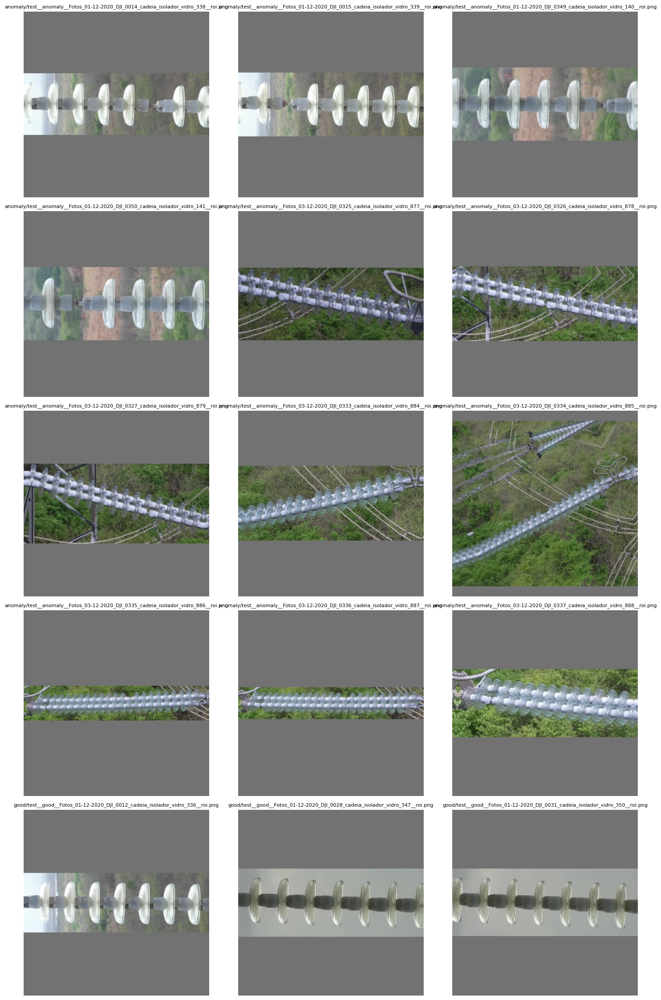

In [5]:
from insulator_anomaly.preprocessing import prepare_processed_datasets
from insulator_anomaly.inspection import show_rois

GENERATE_DATASETS = False
preprocessing_summary = prepare_processed_datasets(config, generate=GENERATE_DATASETS)
print(preprocessing_summary)
show_rois(config)


## 5. Treinar — opcional

O treino usa `train/good`; a avaliação fica na seção seguinte. Checkpoints compatíveis são reutilizados. Checkpoints antigos ou incompatíveis bloqueiam a sobrescrita por padrão. Para outro experimento, prefira um novo destino; `force_modes` permite substituir um treino explicitamente.

Os splits são passados ao Anomalib: `test_split_mode="from_dir"` e `val_split_mode="none"`. Sem validação, não há calibração independente dos limiares/normalização. Não trate as decisões de um treino novo como calibradas: reserve validação própria antes de definir um protocolo de produção. Os checkpoints antigos continuam disponíveis para inferência.


In [ ]:
from insulator_anomaly.training import train_all

RUN_TRAINING = False
if RUN_TRAINING:
    reports = train_all(config)
else:
    print("Treino desativado. Continue para avaliar os checkpoints salvos.")


## 6. Avaliar os checkpoints e comparar os resultados

Avalia todas as imagens das pastas de teste e verifica cobertura exata, sem recalibrar o checkpoint. Exporta scores, FP/FN, AUROC, average precision e curva precision–recall. AP e área trapezoidal da curva PR são métricas distintas.

O limiar para recall de 99% é escolhido no próprio teste e permanece identificado como exploratório, separado da decisão original do checkpoint. Os três modos atuais têm conjuntos diferentes; seus resultados não isolam o efeito do fundo. Consulte as contagens em `PROJECT_REVIEW.md`.


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.
/usr/local/l

model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.



original / checkpoint: TN=422, FP=125, FN=17, TP=64
              precision    recall  f1-score   support

      normal     0.9613    0.7715    0.8560       547
    anomalia     0.3386    0.7901    0.4741        81

    accuracy                         0.7739       628
   macro avg     0.6499    0.7808    0.6650       628
weighted avg     0.8810    0.7739    0.8067       628


original / recall_exploratorio: TN=233, FP=314, FN=0, TP=81
              precision    recall  f1-score   support

      normal     1.0000    0.4260    0.5974       547
    anomalia     0.2051    1.0000    0.3403        81

    accuracy                         0.5000       628
   macro avg     0.6025    0.7130    0.4689       628
weighted avg     0.8975    0.5000    0.5643       628



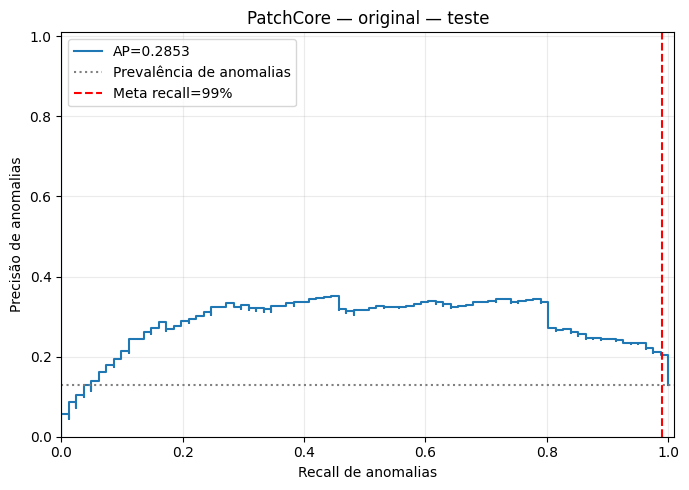

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.
INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec,


blur / checkpoint: TN=487, FP=60, FN=34, TP=47
              precision    recall  f1-score   support

      normal     0.9347    0.8903    0.9120       547
    anomalia     0.4393    0.5802    0.5000        81

    accuracy                         0.8503       628
   macro avg     0.6870    0.7353    0.7060       628
weighted avg     0.8708    0.8503    0.8588       628


blur / recall_exploratorio: TN=327, FP=220, FN=0, TP=81
              precision    recall  f1-score   support

      normal     1.0000    0.5978    0.7483       547
    anomalia     0.2691    1.0000    0.4241        81

    accuracy                         0.6497       628
   macro avg     0.6346    0.7989    0.5862       628
weighted avg     0.9057    0.6497    0.7065       628



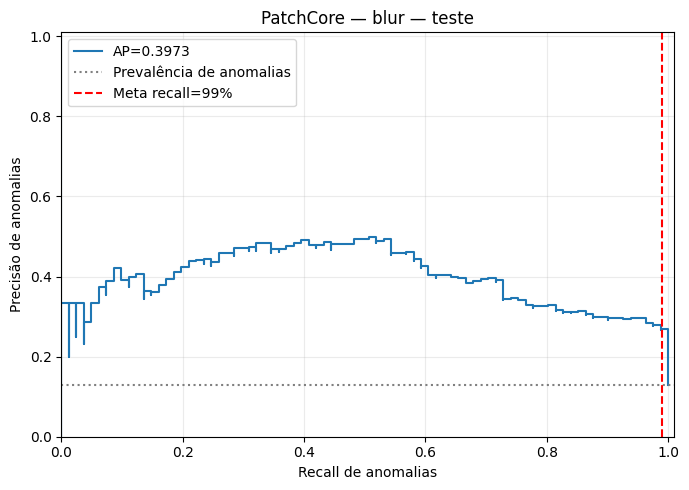

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.
INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec,


gray / checkpoint: TN=464, FP=83, FN=22, TP=59
              precision    recall  f1-score   support

      normal     0.9547    0.8483    0.8984       547
    anomalia     0.4155    0.7284    0.5291        81

    accuracy                         0.8328       628
   macro avg     0.6851    0.7883    0.7138       628
weighted avg     0.8852    0.8328    0.8507       628


gray / recall_exploratorio: TN=286, FP=261, FN=0, TP=81
              precision    recall  f1-score   support

      normal     1.0000    0.5229    0.6867       547
    anomalia     0.2368    1.0000    0.3830        81

    accuracy                         0.5844       628
   macro avg     0.6184    0.7614    0.5348       628
weighted avg     0.9016    0.5844    0.6475       628



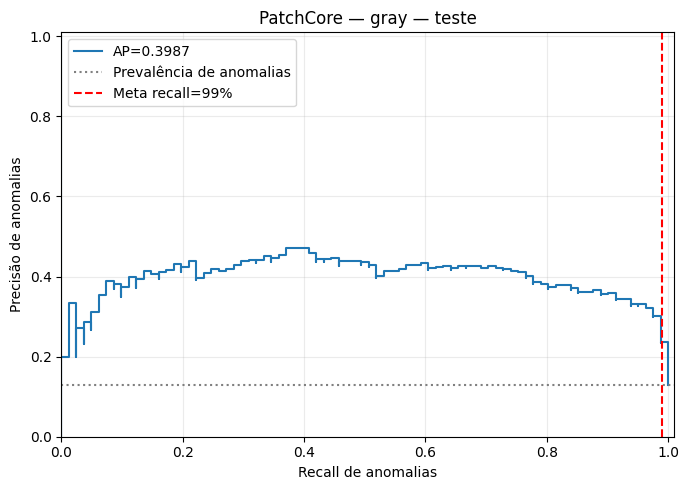

,mode,n_good,n_anomaly,AP,PR_AUC_trapezoidal,recall_checkpoint,FP_checkpoint,FN_checkpoint,limiar_exploratorio,recall_exploratorio,FPR_exploratorio
0,original,547,81,0.285275,0.280605,0.790123,125,17,0.240646,1.0,0.574040
1,blur,547,81,0.397276,0.389330,0.580247,60,34,0.221925,1.0,0.402194
2,gray,547,81,0.398681,0.392120,0.728395,83,22,0.265432,1.0,0.477148


In [6]:
from insulator_anomaly.evaluation import evaluate_all

evaluations, comparison = evaluate_all(config, target_recall=0.99)
display(comparison)


## 7. Inspecionar falsos positivos e falsos negativos


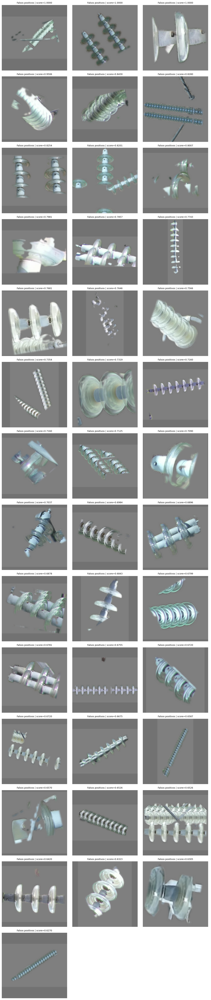

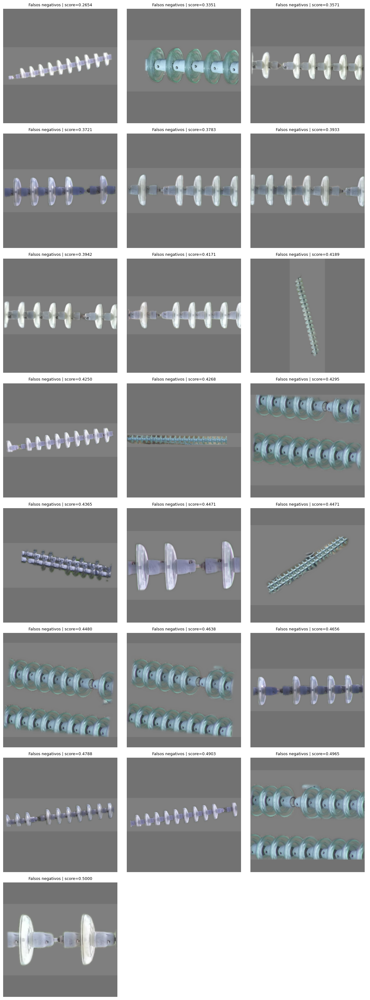

In [7]:
from insulator_anomaly.inspection import show_error_cases

INSPECT_MODE = "gray"
show_error_cases(evaluations[INSPECT_MODE][0], limit=40)


## 8. Falsos negativos em quatro painéis — opcional

Mantém a análise original: imagem de origem quando houver vínculo único, entrada processada, mapa de anomalia e distribuição dos scores. Seleciona FN entre 0,25 e 0,50 e executa apenas inferência. Os mapas usam escala comum dentro de cada modo.


In [ ]:
from insulator_anomaly.inspection import analyze_false_negatives

analysis_table = analyze_false_negatives(
    config, evaluations, modes=("gray",), score_range=(0.25, 0.50), show_first=20,
)
display(analysis_table)


## 9. Análise quantitativa dos mapas de calor

Compara FN, FP, TP e TN com imagens boas: pico, média dos 1% maiores valores, área acima do limiar, componentes conectados, concentração na borda e gradiente espacial suavizado. Exporta mapas, figuras e CSVs. O gradiente mede transições, em unidades do mapa/pixel; uma região alta e uniforme pode ter gradiente baixo.

O limiar pixel é o quantil 99,5% de uma amostra reproduzível de até 32 imagens `test/good`, incluindo possíveis FP. A varredura dos quantis 95%, 99%, 99,5% e 99,9% mostra sensibilidade ao limiar. Os percentis são descritivos e referências podem também ser casos analisados (`is_reference`). Não são probabilidades nem validação independente.

Cada modo tem sua própria escala e referência. Sem min-max por imagem. O limiar de classificação da imagem não é usado como limiar pixel. A amostra padrão de até 40 imagens por grupo não estima o desempenho de todo o teste; use `max_per_group=None` para analisar todos.

Máscaras opcionais: `roi_root` contém máscaras do objeto e `defect_root` contém anotações reais dos defeitos, ambas alinhadas à entrada processada em `<raiz>/<modo>/test/<good ou anomaly>/<nome>.png`, em 0/1 ou 0/255. Nas imagens boas, a máscara de defeito deve ser zero. Calcula IoU, Dice e cobertura quando houver anotações. Máscaras YOLO do objeto não são anotações de defeito. Sem ROI, fundo e letterbox entram na análise; a borda medida é a do quadro. Sem máscaras de defeito, não se mede acerto espacial.

Resultados ficam em `patchcore_insulators/results/<modo>/heatmap_analysis/` e são copiados para o destino persistente. Consulte `heatmap_metrics.csv`, `threshold_sweep.csv`, `group_summary.csv` e `analysis_config.json`.


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.
INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec,

gray: 20/167 mapas calculados.


INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE

gray: 40/167 mapas calculados.


INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE

...

gray: 140/167 mapas calculados.


INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE

gray: 160/167 mapas calculados.


INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE

gray: 167/167 mapas calculados.


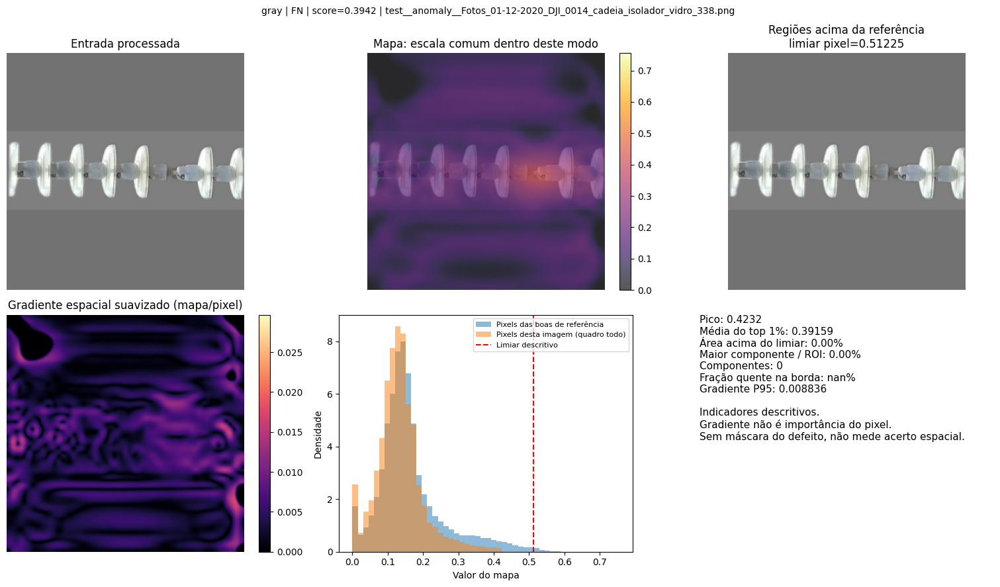

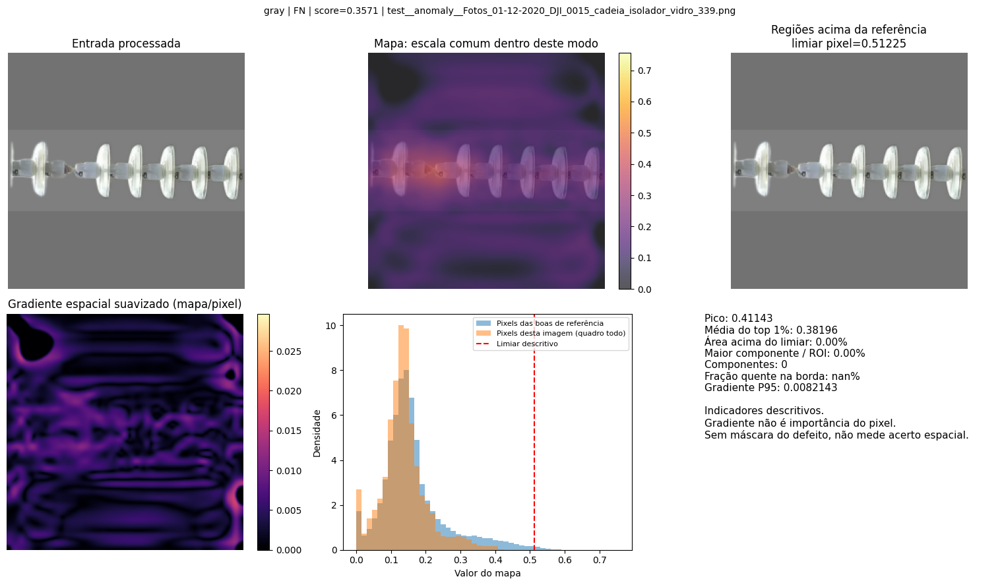

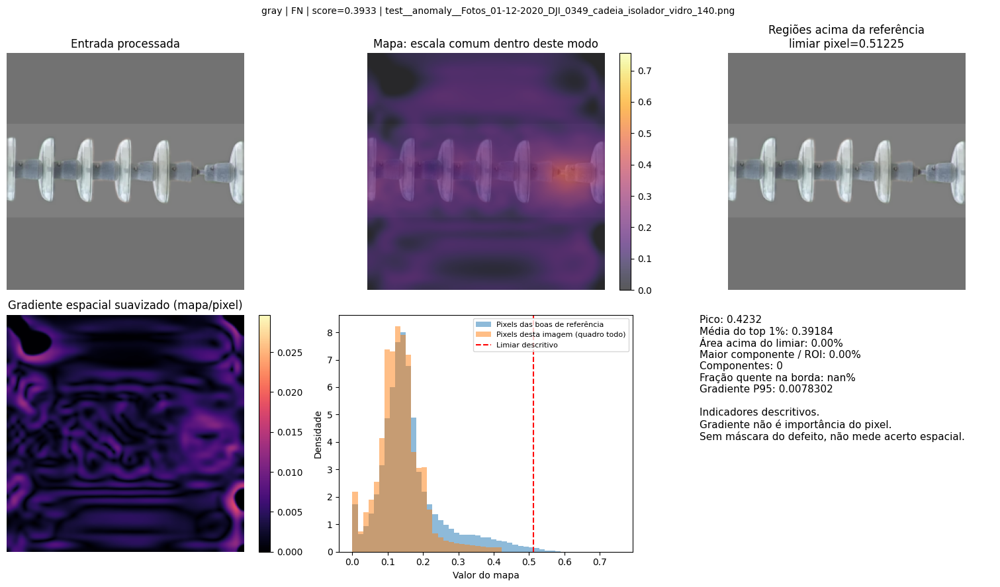

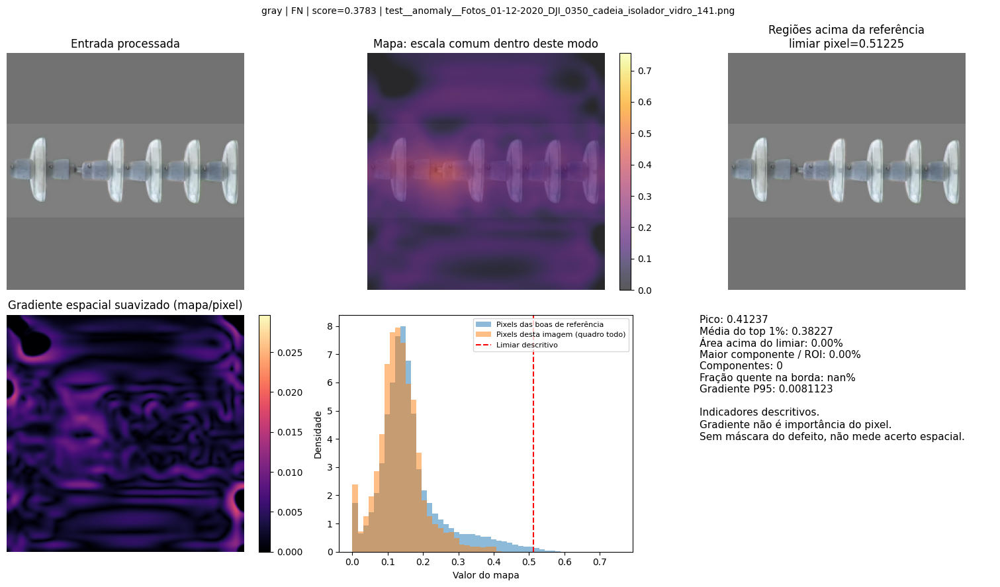

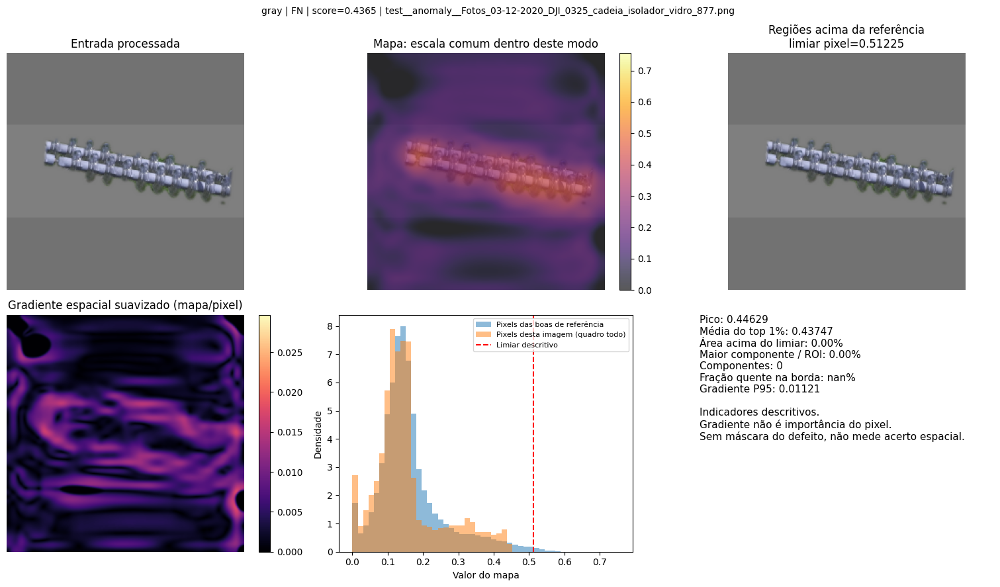

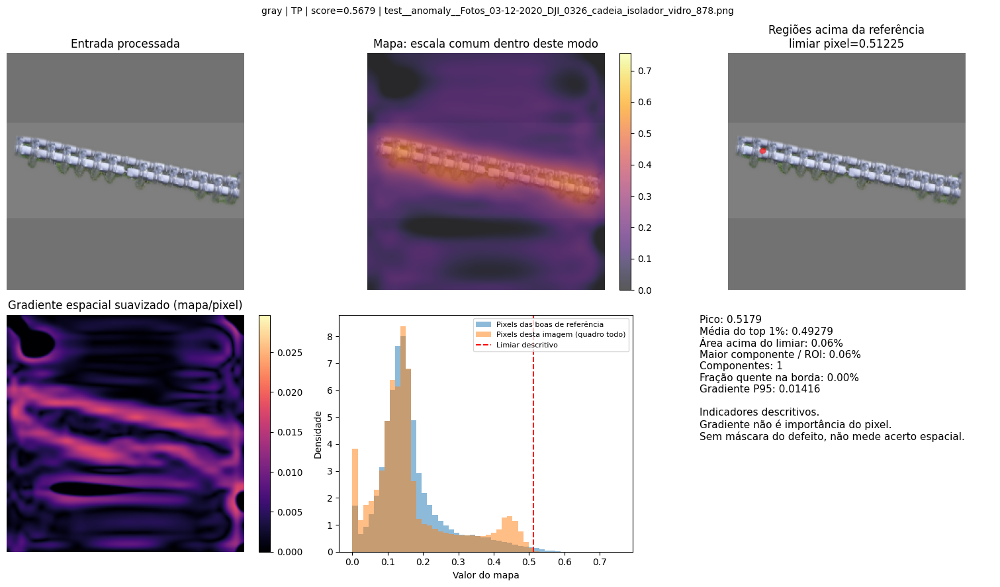

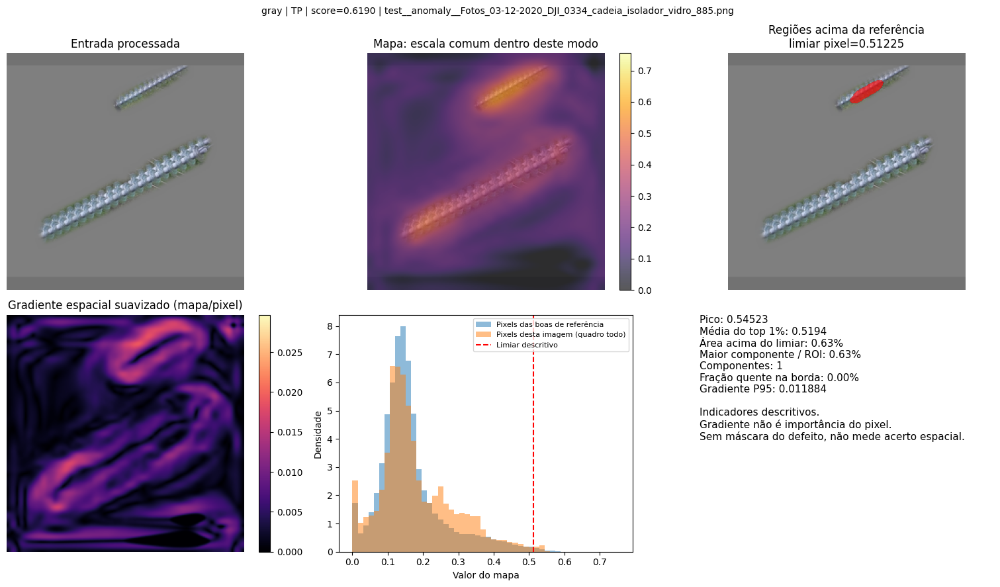

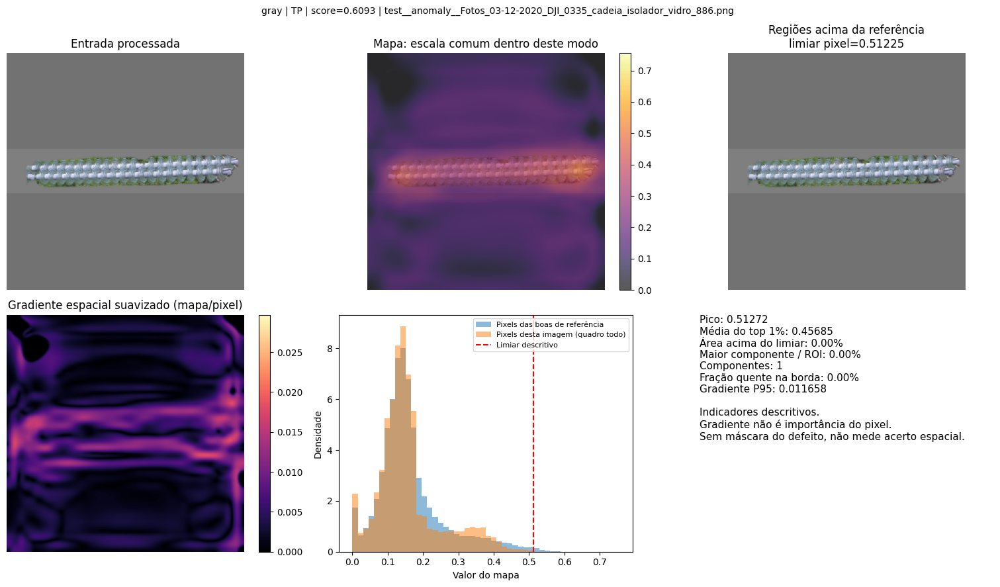

In [ ]:
from insulator_anomaly.heatmaps import run_heatmap_analysis

heatmap_table = run_heatmap_analysis(
    config, evaluations, modes=("gray",), max_per_group=40, reference_count=32, show_first=8,
)
display(heatmap_table[heatmap_table.is_case].sort_values(
    ["group", "top1_mean_normal_percentile"], ascending=[True, False]))


In [4]:
from pathlib import Path
import pandas as pd

arquivo = (
    Path(config.persistent_results_root)
    / "gray"
    / "heatmap_analysis"
    / "heatmap_metrics.csv"
)

print("Arquivo:", arquivo)
heatmap_table = pd.read_csv(arquivo)

Arquivo: /content/drive/MyDrive/Colab_Notebooks/anomalib_glass/patchcore_insulators/results/gray/heatmap_analysis/heatmap_metrics.csv


In [5]:
import pandas as pd
from IPython.display import display

colunas = [
    "group",
    "pred_score",
    "map_peak",
    "top1_mean",
    "hot_area_fraction",
    "largest_component_fraction",
    "components",
    "hot_border_share",
    "gradient_p95",
    "top1_mean_normal_percentile",
]

tabela = heatmap_table.loc[heatmap_table["is_case"]].sort_values(
    ["group", "top1_mean_normal_percentile"],
    ascending=[True, False],
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", 60,
):
    display(tabela[colunas])

,group,pred_score,map_peak,top1_mean,hot_area_fraction,largest_component_fraction,components,hot_border_share,gradient_p95,top1_mean_normal_percentile
4,FN,0.436508,0.446290,0.437474,0.000000,0.000000,0,NaN,0.011210,75.0000
20,FN,0.500000,0.498587,0.477397,0.000000,0.000000,0,NaN,0.009545,75.0000
22,FN,0.478836,0.468433,0.439348,0.000000,0.000000,0,NaN,0.010865,75.0000
24,FN,0.490300,0.478799,0.438721,0.000000,0.000000,0,NaN,0.010457,75.0000
48,FN,0.447090,0.458539,0.435744,0.000000,0.000000,0,NaN,0.010958,75.0000
55,FN,0.496473,0.467491,0.431195,0.000000,0.000000,0,NaN,0.009630,75.0000
57,FN,0.463845,0.459482,0.427225,0.000000,0.000000,0,NaN,0.009876,75.0000
59,FN,0.447972,0.458068,0.430773,0.000000,0.000000,0,NaN,0.010279,75.0000
0,FN,0.394180,0.423204,0.391591,0.000000,0.000000,0,NaN,0.008836,71.8750
2,FN,0.393298,0.423204,0.391841,0.000000,0.000000,0,NaN,0.007830,71.8750
